# Project 08 · Workshop production and OEE

**Benson M. Merita · MeritaAnalytics** · Tools: Python (pandas, NumPy), Matplotlib, Seaborn

**Business question.** Output is slipping and the scrap bin is filling. Which machine, shift and cause is behind it, and what should the owner fix first?

**Data.** Six months of shift logs (April to September 2025, 2,367 rows) from a small metal workshop with five machines in series: Saw → Lathe → Mill → Drill → Grinder. The log was typed by hand, so it has misspelt names, impossible values and duplicates. Synthetic, generated with a fixed seed.

| Step | What it answers |
|---|---|
| 1 | Inspect the raw log |
| 2 | Clean, with a row-count log |
| 3 | OEE by machine |
| 4 | Why is time lost? (downtime Pareto) |
| 5 | Scrap and downtime by machine and shift |
| 6 | Which machine is the bottleneck? |
| 7 | When did the Mill start to slip? |
| 8 | The Grinder's night shift |
| 9 | Final checks |

## Setup

In [1]:
import difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, GREY, DARK, AMBER = "#1F5FD6", "#9CA3AF", "#0B2A4A", "#B45309"
plt.rcParams.update({"figure.figsize": (10, 3.6), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120)

ORDER = ["Saw", "Lathe", "Mill", "Drill", "Grinder"]      # the five machines, in line order
SHIFTS = ["Morning", "Afternoon", "Night"]
PLANNED = 450                                             # planned minutes per shift
log = pd.read_csv("../datasets/08-workshop-production/raw/shift_log.csv")

## Step 1 · Inspect the raw log

In [2]:
print(log.shape, "| exact duplicates:", int(log.duplicated().sum()), "| machine spellings:", log["machine"].nunique())
print("shift spellings:", sorted(log["shift"].unique()))
print("scrap above output:", int((log["scrap_pieces"] > log["total_pieces"]).sum()),
      "| dates that do not exist:", int(pd.to_datetime(log["date"], format="%Y-%m-%d", errors="coerce").isna().sum()))
log[["downtime_min", "actual_cycle_sec", "total_pieces", "scrap_pieces"]].describe().loc[["min", "50%", "max"]].round(1)

(2367, 13) | exact duplicates: 12 | machine spellings: 24
shift spellings: ['A', 'Afternoon', 'Morning', 'Night', 'morning', 'night']
scrap above output: 5 | dates that do not exist: 4


,downtime_min,actual_cycle_sec,total_pieces,scrap_pieces
min,-15.0,0.0,77.0,0.0
50%,21.0,105.4,237.0,3.0
max,900.0,9999.0,4990.0,253.0


## Step 2 · Clean, with a row-count log

**What:**
- Remove exact duplicates.
- Fix machine names: trim spaces and fix capitals, then repair typos such as "Grindr" with the closest valid name.
- Standardise shifts to Morning, Afternoon or Night.
- **Reject** rows that cannot be true (non-existent date, downtime longer than the shift, more scrap than output, output above 1.5× the theoretical maximum), each with a reason.
- Set impossible cycle times and negative or missing downtime to *missing*, rather than dropping the whole row.

**Why:** every raw row is accounted for (**raw = duplicates + rejected + clean**), and good information in a row is not thrown away because of one bad field.

In [3]:
df = log.drop_duplicates().copy()
n_dups = len(log) - len(df)
df["machine"] = df["machine"].str.strip().str.title()
unknown = ~df["machine"].isin(ORDER)
closest = lambda name: (difflib.get_close_matches(name, ORDER, n=1, cutoff=0.7) or [None])[0]
fix = {name: closest(name) for name in df.loc[unknown, "machine"].unique()}
df.loc[unknown, "machine"] = df.loc[unknown, "machine"].map(fix)
print("misspelt names repaired:", int(unknown.sum()), fix)
df["shift"] = df["shift"].str.strip().str[0].str.upper().map({"M": "Morning", "A": "Afternoon", "N": "Night"})
df["date"] = pd.to_datetime(df["date"], format="%Y-%m-%d", errors="coerce")

theory = PLANNED * 60 / df["ideal_cycle_sec"]
reason = np.select([df["date"].isna(), df["downtime_min"] > PLANNED, df["scrap_pieces"] > df["total_pieces"],
                    df["total_pieces"] > 1.5 * theory],
                   ["invalid date", "downtime above planned time", "scrap exceeds output", "output over 1.5x theory"], default="")
rejects = df[reason != ""].assign(reason=reason[reason != ""])
df = df[reason == ""].copy()

cyc_bad = ~df["actual_cycle_sec"].between(0.5 * df["ideal_cycle_sec"], 3 * df["ideal_cycle_sec"])
df.loc[cyc_bad, "actual_cycle_sec"] = np.nan
dt_bad = df["downtime_min"].isna() | (df["downtime_min"] < 0)
df.loc[dt_bad, "downtime_min"] = np.nan

print(f"raw {len(log)} = duplicates {n_dups} + rejected {len(rejects)} + clean {len(df)} ->",
      len(log) == n_dups + len(rejects) + len(df))
print("rejected by reason:", rejects["reason"].value_counts().to_dict())
print("cycle times set missing:", int(cyc_bad.sum()), "| downtime set missing:", int(dt_bad.sum()))

misspelt names repaired: 8 {'Grindr': 'Grinder', 'Mil': 'Mill', 'Dril': 'Drill', 'Saww': 'Saw'}
raw 2367 = duplicates 12 + rejected 19 + clean 2336 -> True
rejected by reason: {'output over 1.5x theory': 6, 'scrap exceeds output': 5, 'downtime above planned time': 4, 'invalid date': 4}
cycle times set missing: 10 | downtime set missing: 20


## Step 3 · OEE by machine

**What:** **OEE (overall equipment effectiveness)** = Availability × Performance × Quality.
- *Availability*: share of planned time the machine actually ran.
- *Performance*: how fast it ran against the standard cycle time.
- *Quality*: share of pieces that were good.

**Why:** OEE is the standard factory measure. Splitting it into three parts shows *which kind* of loss to fix. Rows with unknown downtime are left out of OEE.

In [4]:
df["good_pieces"] = df["total_pieces"] - df["scrap_pieces"]
df["run_min"] = df["planned_min"] - df["downtime_min"]
df["cycle_ratio"] = df["actual_cycle_sec"] / df["ideal_cycle_sec"]
df["scrap_loss_ksh"] = df["scrap_pieces"] * df["unit_value_ksh"]
df["week"] = df["date"].dt.to_period("W").dt.start_time

ok = df[df["downtime_min"].notna()].copy()
ok["ideal_min"] = ok["ideal_cycle_sec"] * ok["total_pieces"] / 60

def oee_table(g):
    a = g["run_min"].sum() / g["planned_min"].sum()
    p = g["ideal_min"].sum() / g["run_min"].sum()
    q = g["good_pieces"].sum() / g["total_pieces"].sum()
    return pd.Series({"availability_pct": 100 * a, "performance_pct": 100 * p, "quality_pct": 100 * q, "oee_pct": 100 * a * p * q})

oee = ok.groupby("machine").apply(oee_table, include_groups=False).loc[ORDER]
plant = oee_table(ok)
print(f"plant OEE {plant['oee_pct']:.1f}% = availability {plant['availability_pct']:.1f}% "
      f"x performance {plant['performance_pct']:.1f}% x quality {plant['quality_pct']:.1f}%")
oee.round(1)

plant OEE 83.3% = availability 93.3% x performance 90.5% x quality 98.6%


,availability_pct,performance_pct,quality_pct,oee_pct
machine,,,,
Saw,95.3,91.0,99.4,86.2
Lathe,93.1,90.6,98.8,83.3
Mill,90.5,89.4,98.5,79.7
Drill,94.2,90.8,98.2,84.0
Grinder,93.3,90.8,97.2,82.3


## Step 4 · Why is time lost? (downtime Pareto)

**What:** total downtime minutes by reason, largest first, with the running share.
**Why:** a Pareto chart shows the few causes behind most of the lost time, so effort goes where it pays.

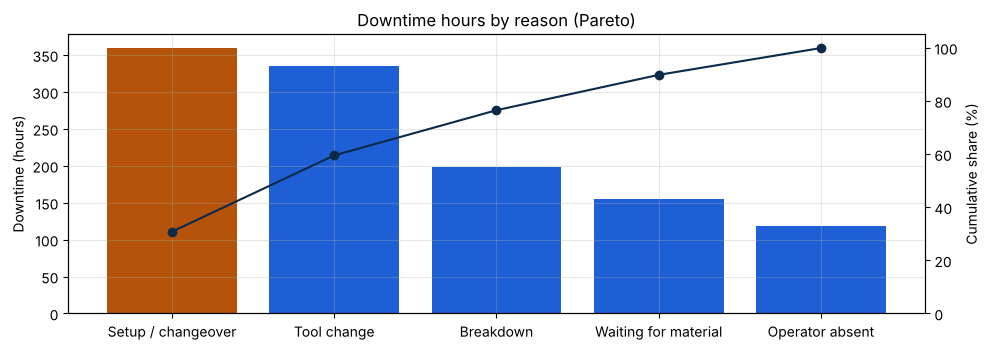

,minutes,share_pct,cumulative_pct
downtime_reason,,,
Setup / changeover,21589.0,30.8,30.8
Tool change,20092.0,28.7,59.5
Breakdown,11928.0,17.0,76.5
Waiting for material,9331.0,13.3,89.8
Operator absent,7100.0,10.1,99.9


In [5]:
par = df[df["downtime_reason"] != "No stop"].groupby("downtime_reason")["downtime_min"].sum().sort_values(ascending=False)
par_tbl = pd.DataFrame({"minutes": par, "share_pct": (100 * par / par.sum()).round(1)})
par_tbl["cumulative_pct"] = par_tbl["share_pct"].cumsum().round(1)

fig, ax = plt.subplots()
ax.bar(par.index, par.values / 60, color=[AMBER if i == 0 else BLUE for i in range(len(par))])
ax.set_title("Downtime hours by reason (Pareto)"); ax.set_ylabel("Downtime (hours)")
ax2 = ax.twinx(); ax2.plot(par.index, par_tbl["cumulative_pct"], color=DARK, marker="o")
ax2.set_ylabel("Cumulative share (%)"); ax2.set_ylim(0, 105); ax2.grid(False)
plt.tight_layout(); plt.show()
par_tbl

## Step 5 · Scrap and downtime by machine and shift

**What:** scrap rate and the shilling value of scrap per machine, then two heat maps: average downtime and scrap rate for every machine and shift.
**Why:** a problem that sits in one machine *on one shift* points to people, handover or lighting, not the machine itself.

,scrap_rate_pct,loss_ksh,share_of_scrap_loss_pct
machine,,,
Saw,0.62,366092.33,10.53
Lathe,1.25,366713.79,10.55
Mill,1.49,401803.39,11.56
Drill,1.83,935929.71,26.93
Grinder,2.79,1405340.88,40.43


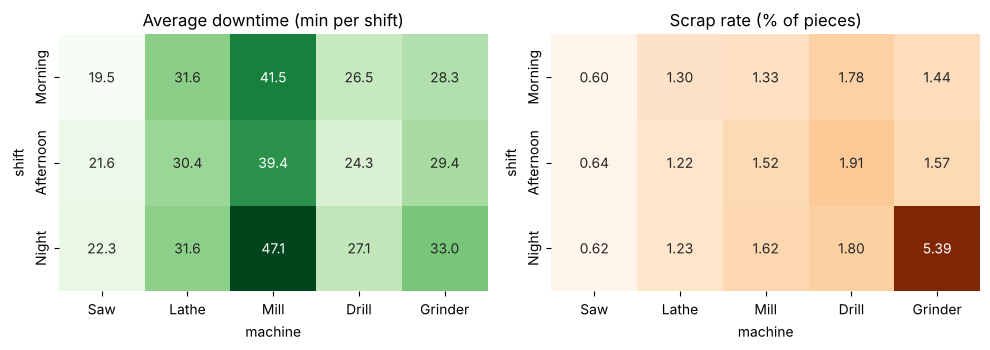

In [6]:
q = df.groupby("machine").agg(pieces=("total_pieces", "sum"), scrap=("scrap_pieces", "sum"), loss_ksh=("scrap_loss_ksh", "sum"))
q["scrap_rate_pct"] = 100 * q["scrap"] / q["pieces"]
q["share_of_scrap_loss_pct"] = 100 * q["loss_ksh"] / q["loss_ksh"].sum()
display(q.loc[ORDER, ["scrap_rate_pct", "loss_ksh", "share_of_scrap_loss_pct"]].round(2))

dt_p = df.pivot_table(index="shift", columns="machine", values="downtime_min", aggfunc="mean")[ORDER].loc[SHIFTS]
sums = df.groupby(["shift", "machine"])[["scrap_pieces", "total_pieces"]].sum()
sc_p = (100 * sums["scrap_pieces"] / sums["total_pieces"]).unstack()[ORDER].loc[SHIFTS]
fig, ax = plt.subplots(1, 2)
sns.heatmap(dt_p, annot=True, fmt=".1f", cmap="Greens", cbar=False, ax=ax[0])
ax[0].set_title("Average downtime (min per shift)")
sns.heatmap(sc_p, annot=True, fmt=".2f", cmap="Oranges", cbar=False, ax=ax[1])
ax[1].set_title("Scrap rate (% of pieces)")
for a in ax:
    a.grid(False)
plt.tight_layout(); plt.show()

## Step 6 · Which machine is the bottleneck?

**What:** average good pieces per shift for each machine, against what it could make in a full shift at its standard cycle time.
**Why:** the machines run in series, so the line can only go as fast as its slowest machine. A minute lost there is lost for the whole workshop.

In [7]:
cap = df.groupby("machine").agg(good_per_shift=("good_pieces", "mean"))
cap["theoretical_per_shift"] = (PLANNED * 60 / df["ideal_cycle_sec"]).groupby(df["machine"]).mean()
cap["pct_of_theory"] = 100 * cap["good_per_shift"] / cap["theoretical_per_shift"]
cap = cap.loc[ORDER]
bottleneck = cap["good_per_shift"].idxmin()
print("bottleneck:", bottleneck)
cap.round(1)

bottleneck: Mill


,good_per_shift,theoretical_per_shift,pct_of_theory
machine,,,
Saw,527.6,612.2,86.2
Lathe,211.8,254.7,83.2
Mill,159.2,199.6,79.8
Drill,261.0,310.5,84.1
Grinder,229.9,278.9,82.4


## Step 7 · When did the Mill start to slip?

**What:** weekly average downtime per machine. Take the Mill's normal level as the median of its first 8 weeks, and flag the first week where it runs above **1.5× that baseline for three weeks in a row**. Then compare the Mill before and after that week.
**Why:** a simple, explainable alert rule that does not fire on one bad week.

Mill baseline 33.4 min | alert above 50.2 min | first sustained bad week: 2025-09-01


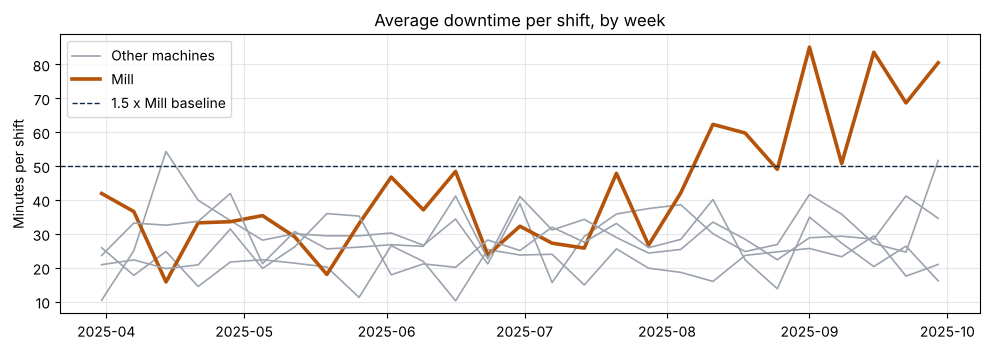

In [8]:
wk = df.pivot_table(index="week", columns="machine", values="downtime_min", aggfunc="mean")[ORDER]
baseline = wk["Mill"].iloc[:8].median()
threshold = 1.5 * baseline
hot = wk["Mill"] > threshold
sustained = hot & hot.shift(-1, fill_value=False) & hot.shift(-2, fill_value=False)
first_bad = wk.index[sustained][0]
print(f"Mill baseline {baseline:.1f} min | alert above {threshold:.1f} min | first sustained bad week: {first_bad.date()}")

fig, ax = plt.subplots()
for mname in ORDER:
    ax.plot(wk.index, wk[mname], color=AMBER if mname == "Mill" else GREY, lw=2.6 if mname == "Mill" else 1.2,
            label="Mill" if mname == "Mill" else ("Other machines" if mname == "Saw" else None))
ax.axhline(threshold, color=DARK, ls="--", lw=1, label="1.5 x Mill baseline")
ax.set_title("Average downtime per shift, by week"); ax.set_ylabel("Minutes per shift"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

In [9]:
mill = df[df["machine"] == "Mill"].copy()
mill["period"] = np.where(mill["date"] >= first_bad, "from alert week", "before")
def summarise(g):
    return pd.Series({"shifts": len(g), "downtime_min": g["downtime_min"].mean(),
                      "scrap_rate_pct": 100 * g["scrap_pieces"].sum() / g["total_pieces"].sum(),
                      "good_per_shift": g["good_pieces"].mean()})
display(mill.groupby("period").apply(summarise, include_groups=False).round(2))

reasons = mill[mill["downtime_reason"] != "No stop"].groupby(["period", "downtime_reason"])["downtime_min"].sum().unstack(0).fillna(0)
share = (100 * reasons / reasons.sum()).round(1)
share["change_pts"] = share["from alert week"] - share["before"]
share.sort_values("change_pts", ascending=False)

,shifts,downtime_min,scrap_rate_pct,good_per_shift
period,,,,
before,391.0,36.65,1.41,162.35
from alert week,78.0,72.69,1.96,143.49


period,before,from alert week,change_pts
downtime_reason,,,
Tool change,28.4,57.6,29.2
Waiting for material,14.6,12.1,-2.5
Operator absent,11.6,8.6,-3.0
Setup / changeover,24.8,15.0,-9.8
Breakdown,20.5,6.7,-13.8


After the alert week the Mill's downtime roughly doubles, and **tool changes** become the main cause. That points to worn cutters, inserts or coolant.

## Step 8 · The Grinder's night shift

In [10]:
gr = df[df["machine"] == "Grinder"]
gs = gr.groupby("shift").agg(pieces=("total_pieces", "sum"), scrap=("scrap_pieces", "sum"), loss_ksh=("scrap_loss_ksh", "sum"))
gs["scrap_rate_pct"] = 100 * gs["scrap"] / gs["pieces"]
monthly_night = gr[gr["shift"] == "Night"].groupby(gr["date"].dt.to_period("M")).apply(
    lambda x: 100 * x["scrap_pieces"].sum() / x["total_pieces"].sum(), include_groups=False)
print("Grinder night-shift scrap rate by month (%):", monthly_night.round(2).tolist())
gs.loc[SHIFTS].round({"scrap_rate_pct": 2, "loss_ksh": 0})

Grinder night-shift scrap rate by month (%): [5.93, 5.61, 5.31, 5.0, 5.18, 5.29]


,pieces,scrap,loss_ksh,scrap_rate_pct
shift,,,,
Morning,37242,538,237864.0,1.44
Afternoon,36560,573,267143.0,1.57
Night,36387,1961,900334.0,5.39


The night-shift scrap rate is high in **every** month, not just one, so it is a standing practice issue rather than a one-off.

## Step 9 · Final checks

In [11]:
checks = {
    "raw = clean + rejected + duplicates": len(log) == len(df) + len(rejects) + n_dups,
    "machine names are the five allowed values": sorted(df["machine"].unique()) == sorted(ORDER),
    "shifts are the three allowed values": sorted(df["shift"].unique()) == sorted(SHIFTS),
    "scrap never above output": bool((df["scrap_pieces"] <= df["total_pieces"]).all()),
    "log_id is unique": bool(df["log_id"].is_unique),
}
for name, ok_ in checks.items():
    print("PASS" if ok_ else "FAIL", "-", name)

PASS - raw = clean + rejected + duplicates
PASS - machine names are the five allowed values
PASS - shifts are the three allowed values
PASS - scrap never above output
PASS - log_id is unique


## Key findings and recommendations

- **Plant OEE is about 83%.** The **Mill** is both the bottleneck and the machine with the lowest OEE.
- **Setups and tool changes** cause most of the lost minutes.
- From its alert week the **Mill's downtime doubled**, driven by tool changes. *Inspect its cutters, inserts and coolant now, and do setups between batches with spare tooling kept at the Mill.*
- The **Grinder scraps over three times as much on nights** (about 5.4% against 1.4–1.6% by day), the largest single source of scrap cost. *Review first-piece inspection, lighting and handover on that shift.*
- *Add an alert when any machine runs above 1.5× its own downtime baseline for three weeks, and use drop-down lists for machine and shift names at data entry.*

**Limitations.** Synthetic data with the two problems planted on purpose. Shilling values per piece are illustrative.